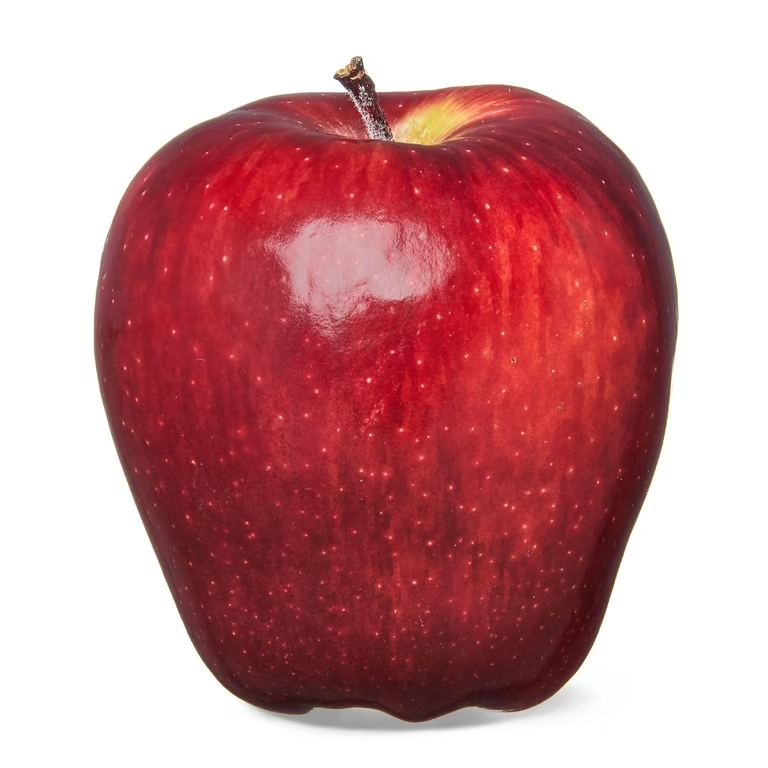

# 🎬 Finding Your Movie Twin: The FlickPick Story

## A Hands-On Journey Through Vectors, Distances, Similarity & Scaling

---

**The Setup:**

You've just been hired as the first data scientist at **FlickPick** — a scrappy little movie streaming startup competing against giants like Netflix and Amazon Prime.

FlickPick has **10,000 users** and a catalog of movies across multiple genres. The CEO walks into your cubicle on Day 1 and says:

> *"We're losing users because our recommendations are terrible. People are watching horror movies and we're suggesting rom-coms. Fix it. You have one week."*

Your mission: **build a recommendation engine that finds users with similar taste and recommends what they loved.**

But wait — how do you even *measure* whether two people have similar taste in movies? How do you turn something as fuzzy as "movie preference" into something a computer can work with?

That's exactly what this notebook is about. Let's figure it out — one step at a time.

---

### 📚 What You'll Learn

| Chapter | Topic | The Question It Answers |
|---------|-------|------------------------|
| 1 | Vectors & Representation | *How do we turn "taste" into numbers?* |
| 2 | Norms (L1 & L2) | *How do we measure the "size" of a vector?* |
| 3 | Euclidean & Manhattan Distance | *How different are two users?* |
| 4 | Cosine Similarity & Angles | *Do two users like the same KIND of movies?* |
| 5 | Curse of Dimensionality | *Why does everything break in high dimensions?* |
| 6 | Feature Scaling | *How do we stop big numbers from bullying small ones?* |

---
## 🛠️ Setup: Loading Our Toolkit

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.metrics.pairwise import cosine_similarity, euclidean_distances
from scipy.spatial.distance import cityblock, pdist
import warnings
warnings.filterwarnings('ignore')

# Styling
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 12
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
sns.set_palette("husl")

print("✅ All libraries loaded. Let's build FlickPick's recommendation engine!")

✅ All libraries loaded. Let's build FlickPick's recommendation engine!


---
# Chapter 1: Turning Taste Into Numbers 🎯

## The Problem

FlickPick has user data — every user rates movies on a scale of **1 to 10**. The platform categorizes movies into **5 genres**: Action, Comedy, Romance, Sci-Fi, and Horror.

For each user, we can compute their **average rating per genre**. For example:

> **Anya** rated 12 action movies with an average of 8.5, 5 comedies at 6.0, 3 romances at 2.0, 8 sci-fi movies at 9.0, and 1 horror at 1.0.

We can write this as: **Anya = [8.5, 6.0, 2.0, 9.0, 1.0]**

That right there? That's a **vector**.

### 🤔 But what IS a vector, really?

A vector is just an **ordered list of numbers** that describes something. Each number sits in a specific position (called a **dimension**), and that position has meaning.

Think of it like an address — the numbers only make sense because we know what each position represents.

| Position | 1 | 2 | 3 | 4 | 5 |
|----------|---|---|---|---|---|
| **Meaning** | Action | Comedy | Romance | Sci-Fi | Horror |
| **Anya** | 8.5 | 6.0 | 2.0 | 9.0 | 1.0 |

This is how machine learning works with *everything* — text, images, audio. **Step 1 is always: turn things into vectors of numbers.** That process is called **representation**.

Let's create FlickPick's user data and see this in action.

In [ ]:
# Let's create 8 users with distinct taste profiles
# Each user is a vector: [Action, Comedy, Romance, Sci-Fi, Horror]

np.random.seed(42)

genres = ['Action', 'Comedy', 'Romance', 'Sci-Fi', 'Horror']

# Hand-crafted users with clear personality types
users = {
    'Anya':    [8.5, 6.0, 2.0, 9.0, 1.0],   # Action/Sci-Fi lover
    'Ben':     [9.0, 5.5, 1.5, 8.5, 2.0],   # Very similar to Anya
    'Carla':   [2.0, 8.0, 9.5, 1.5, 3.0],   # Rom-com fan
    'Dev':     [1.0, 7.5, 9.0, 2.0, 2.5],   # Similar to Carla
    'Elena':   [5.0, 5.0, 5.0, 5.0, 5.0],   # Watches everything equally
    'Frank':   [2.0, 1.5, 1.0, 2.0, 0.5],   # Casual viewer (low ratings)
    'Grace':   [9.0, 8.5, 7.5, 9.5, 8.0],   # Loves EVERYTHING (enthusiast)
    'Hassan':  [1.5, 3.0, 2.0, 1.0, 9.5],   # Horror fanatic
}

# Create a DataFrame
df = pd.DataFrame(users, index=genres).T
df.index.name = 'User'

print("🎬 FlickPick User Taste Profiles")
print("=" * 50)
print("(Average genre ratings on a 1-10 scale)\n")
display(df)
print(f"\n📊 Each user is a vector with {len(genres)} dimensions (one per genre)")

🎬 FlickPick User Taste Profiles
(Average genre ratings on a 1-10 scale)



,Action,Comedy,Romance,Sci-Fi,Horror
User,,,,,
Anya,8.5,6.0,2.0,9.0,1.0
Ben,9.0,5.5,1.5,8.5,2.0
Carla,2.0,8.0,9.5,1.5,3.0
Dev,1.0,7.5,9.0,2.0,2.5
Elena,5.0,5.0,5.0,5.0,5.0
Frank,2.0,1.5,1.0,2.0,0.5
Grace,9.0,8.5,7.5,9.5,8.0
Hassan,1.5,3.0,2.0,1.0,9.5



📊 Each user is a vector with 5 dimensions (one per genre)


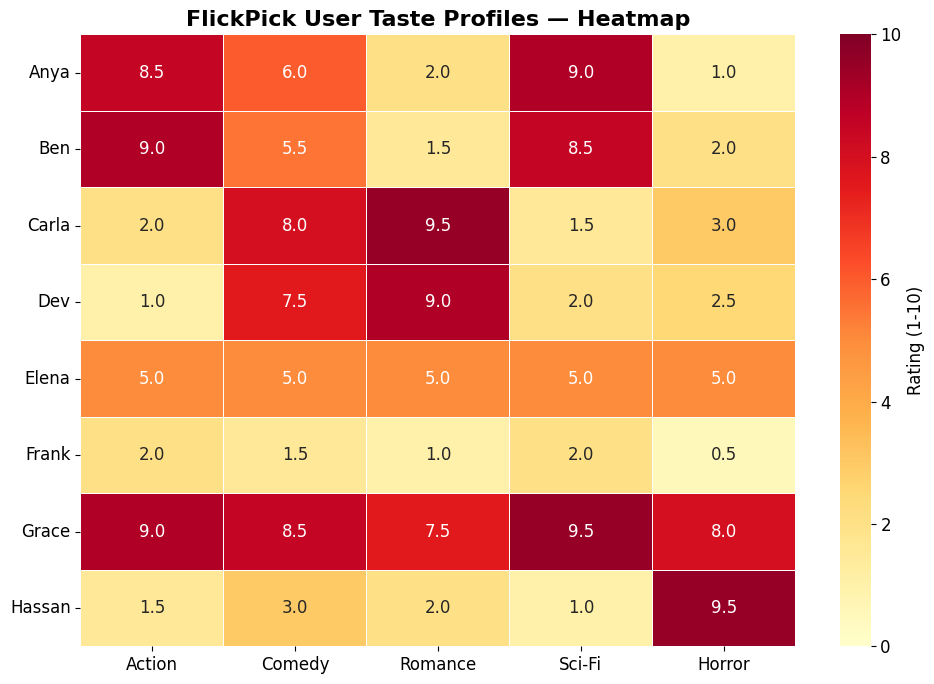

👀 Notice: Anya and Ben have very SIMILAR color patterns (similar taste).
   Grace's row is DARK everywhere — she loves all genres.
   Frank's row is LIGHT everywhere — he's a casual viewer.
   But Grace and Frank might actually like the SAME kinds of movies... 🤔
   (We'll come back to this VERY important observation later!)


In [ ]:
# Visualize: Heatmap of all users' taste profiles

fig, ax = plt.subplots(figsize=(10, 7))

sns.heatmap(df, annot=True, fmt='.1f', cmap='YlOrRd', linewidths=0.5,
            cbar_kws={'label': 'Rating (1-10)'}, ax=ax, vmin=0, vmax=10)
ax.set_title('FlickPick User Taste Profiles — Heatmap', fontsize=16, fontweight='bold')
ax.set_ylabel('')
ax.tick_params(axis='y', rotation=0)

plt.tight_layout()
plt.show()

print("👀 Notice: Anya and Ben have very SIMILAR color patterns (similar taste).")
print("   Grace's row is DARK everywhere — she loves all genres.")
print("   Frank's row is LIGHT everywhere — he's a casual viewer.")
print("   But Grace and Frank might actually like the SAME kinds of movies... 🤔")
print("   (We'll come back to this VERY important observation later!)")

### 💡 Key Insight: Vectors as Identity

Every user is now a **point in 5-dimensional space**. We can't visualize 5D, but the math works the same as 2D or 3D.

The radar charts above are one way to peek at these vectors — the *shape* of the chart tells you what *kind* of movies someone likes, while the *size* tells you how intensely they feel about movies in general.

> **In ML, the first step is always representation: turning real-world things into vectors of numbers.**

Now that everyone is a vector... how do we compare them? Before we can answer that, we need one fundamental concept: **how do you measure the "size" of a vector?**

---
# Chapter 2: Measuring the Size of a Vector — Norms 📏

## Why Do We Need This?

Before we can measure the **distance** between two users (Chapter 3) or the **angle** between them (Chapter 4), we need a more basic building block: a way to measure how "big" a single vector is.

Think of it this way — if someone asks *"how far apart are these two cities?"*, you first need to agree on **how you measure distance**. That's what norms give us. They're not interesting on their own — they're the **engine parts** that power everything we're about to build.

> **A norm is simply a way to assign a single number (a "size" or "length") to a vector.**

There are different ways to do this, and each one leads to a different distance formula later. Let's meet the two most common norms.

---

### 📐 L1 Norm: "The Walking Distance from Zero"

Imagine you're at the **origin** (a user who rated every genre at 0) and you need to reach Anya's point [8.5, 6.0, 2.0, 9.0, 1.0] — but you can only walk along one axis at a time (like a taxi on a grid).

**How far do you walk?** You go 8.5 along Action, then 6.0 along Comedy, then 2.0 along Romance... and add them all up.

$$\|\mathbf{v}\|_1 = |v_1| + |v_2| + \cdots + |v_n|$$

**Just add up the absolute values. That's it.**

### 📐 L2 Norm: "The Straight-Line Distance from Zero"

Now imagine you could **fly** from the origin straight to Anya's point, cutting through the space diagonally. How far is that flight?

This is just the Pythagorean theorem extended to any number of dimensions:

$$\|\mathbf{v}\|_2 = \sqrt{v_1^2 + v_2^2 + \cdots + v_n^2}$$

**Square each value, add them up, take the square root.**

---

### 🏠 A Simple 2D Example First

Before we use our FlickPick data, let's build intuition with a small example we can actually draw.

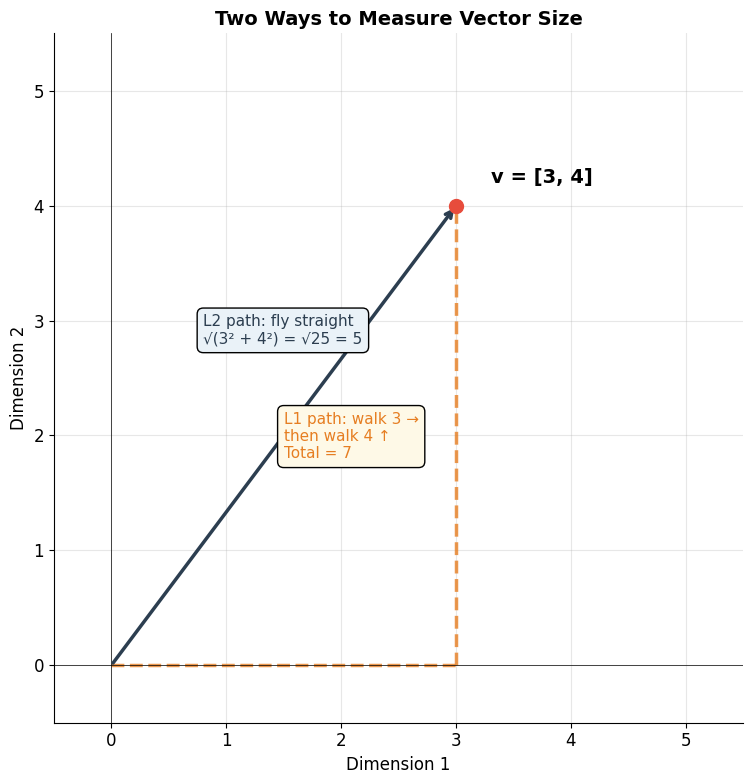

For v = [3, 4]:
   L1 Norm = |3| + |4| = 7      (walk along the grid)
   L2 Norm = √(9 + 16) = √25 = 5  (fly in a straight line)

📐 The L2 norm is always ≤ the L1 norm (straight line is always the shortest path).
   Both measure 'size' — they just measure it differently.


In [ ]:
# Simple 2D example to build intuition

fig, ax = plt.subplots(figsize=(8, 8))

# A simple vector: [3, 4]
v = np.array([3, 4])

# Draw the vector as an arrow
ax.annotate('', xy=(3, 4), xytext=(0, 0),
            arrowprops=dict(arrowstyle='->', lw=2.5, color='#2c3e50'))
ax.plot(3, 4, 'o', markersize=10, color='#e74c3c', zorder=5)
ax.annotate('v = [3, 4]', xy=(3, 4), xytext=(3.3, 4.2), fontsize=14, fontweight='bold')

# L1 Norm path (walk along axes)
ax.plot([0, 3], [0, 0], '--', linewidth=2.5, color='#e67e22', alpha=0.8)
ax.plot([3, 3], [0, 4], '--', linewidth=2.5, color='#e67e22', alpha=0.8)
ax.annotate('L1 path: walk 3 →\nthen walk 4 ↑\nTotal = 7',
            xy=(1.5, 1.8), fontsize=11, color='#e67e22',
            bbox=dict(boxstyle='round,pad=0.4', facecolor='#fef9e7'))

# L2 Norm (straight line — already drawn as the arrow)
ax.annotate('L2 path: fly straight\n√(3² + 4²) = √25 = 5',
            xy=(0.8, 2.8), fontsize=11, color='#2c3e50',
            bbox=dict(boxstyle='round,pad=0.4', facecolor='#eaf2f8'))

# Grid and labels
ax.set_xlim(-0.5, 5.5)
ax.set_ylim(-0.5, 5.5)
ax.set_xlabel('Dimension 1', fontsize=12)
ax.set_ylabel('Dimension 2', fontsize=12)
ax.set_title('Two Ways to Measure Vector Size', fontsize=14, fontweight='bold')
ax.set_aspect('equal')
ax.grid(True, alpha=0.3)
ax.axhline(y=0, color='black', linewidth=0.5)
ax.axvline(x=0, color='black', linewidth=0.5)

plt.tight_layout()
plt.show()

print("For v = [3, 4]:")
print(f"   L1 Norm = |3| + |4| = 7      (walk along the grid)")
print(f"   L2 Norm = √(9 + 16) = √25 = 5  (fly in a straight line)")
print()
print("📐 The L2 norm is always ≤ the L1 norm (straight line is always the shortest path).")
print("   Both measure 'size' — they just measure it differently.")

In [ ]:
# Now let's compute norms for our FlickPick users

norm_data = []

for user, ratings in users.items():
    v = np.array(ratings)
    l1 = np.sum(np.abs(v))
    l2 = np.sqrt(np.sum(v**2))
    norm_data.append({
        'User': user,
        'Vector': str(ratings),
        'L1 Norm': round(l1, 2),
        'L2 Norm': round(l2, 2),
    })

norm_df = pd.DataFrame(norm_data).set_index('User')
print("📏 FlickPick User Norms")
print("=" * 70)
print(norm_df[['L1 Norm', 'L2 Norm']])
print()
print("Both norms tell us something about the 'size' of each user's vector.")
print("Users who rate everything high (Grace) have large norms.")
print("Users who rate everything low (Frank) have small norms.")
print()
print("But here's the key question: does a bigger norm mean 'better taste'")
print("or 'more passionate' or 'more active'? Not necessarily!")
print("It just means their vector is LONGER. What that MEANS depends on context.")

📏 FlickPick User Norms
        L1 Norm  L2 Norm
User                    
Anya       26.5    13.94
Ben        26.5    13.77
Carla      24.0    13.02
Dev        22.0    12.19
Elena      25.0    11.18
Frank       7.0     3.39
Grace      42.5    19.07
Hassan     17.0    10.32

Both norms tell us something about the 'size' of each user's vector.
Users who rate everything high (Grace) have large norms.
Users who rate everything low (Frank) have small norms.

But here's the key question: does a bigger norm mean 'better taste'
or 'more passionate' or 'more active'? Not necessarily!
It just means their vector is LONGER. What that MEANS depends on context.


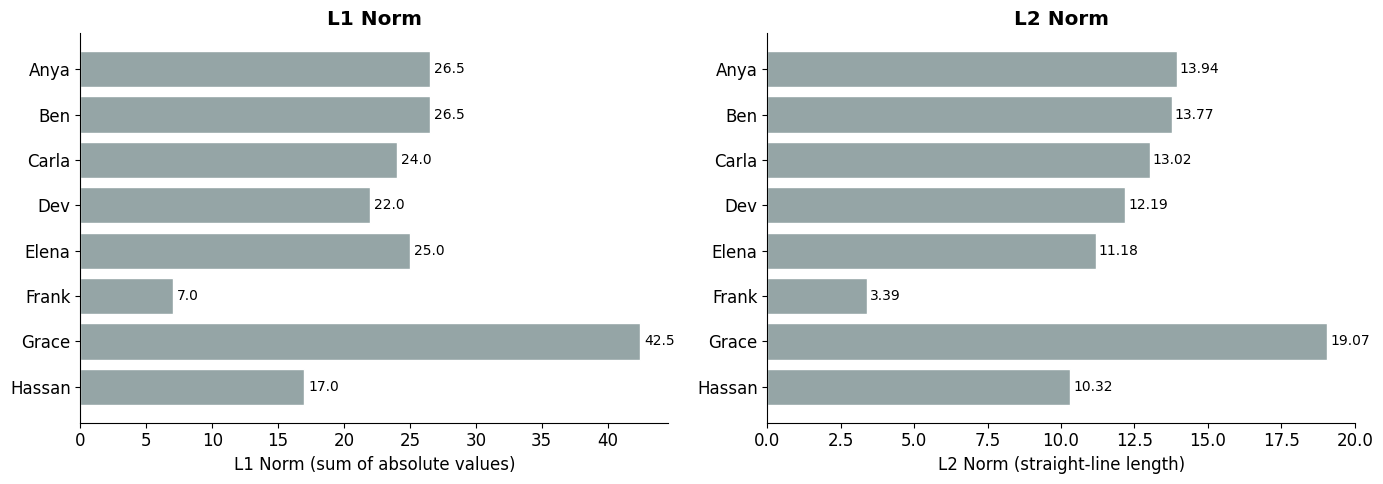

Notice: L1 and L2 rank users in basically the same order here.
That's because they're both measuring 'size' — just with different formulas.
The differences become important when they're used INSIDE other calculations...


In [ ]:
# Visualize norms side by side

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

user_names = list(users.keys())
l1_vals = [norm_df.loc[u, 'L1 Norm'] for u in user_names]
l2_vals = [norm_df.loc[u, 'L2 Norm'] for u in user_names]

colors = ['#95a5a6'] * len(user_names)

axes[0].barh(user_names, l1_vals, color=colors, edgecolor='white')
axes[0].set_xlabel('L1 Norm (sum of absolute values)')
axes[0].set_title('L1 Norm', fontweight='bold')
axes[0].invert_yaxis()
for i, v in enumerate(l1_vals):
    axes[0].text(v + 0.3, i, str(v), va='center', fontsize=10)

axes[1].barh(user_names, l2_vals, color=colors, edgecolor='white')
axes[1].set_xlabel('L2 Norm (straight-line length)')
axes[1].set_title('L2 Norm', fontweight='bold')
axes[1].invert_yaxis()
for i, v in enumerate(l2_vals):
    axes[1].text(v + 0.1, i, str(v), va='center', fontsize=10)

plt.tight_layout()
plt.show()

print("Notice: L1 and L2 rank users in basically the same order here.")
print("That's because they're both measuring 'size' — just with different formulas.")
print("The differences become important when they're used INSIDE other calculations...")

### 💡 Key Insight: Norms Are Building Blocks, Not Answers

On their own, norms just tell you "how long is this vector?" — that's it. They don't inherently mean "enthusiasm" or "intensity" or any other human-friendly label. **Interpretation always depends on your context and your data.**

So why learn them? Because they're the **engine parts** inside almost everything else in ML:

| Where Norms Show Up | How |
|---------------------|-----|
| **Euclidean Distance** (Chapter 3) | Is the L2 norm of the *difference* between two vectors |
| **Manhattan Distance** (Chapter 3) | Is the L1 norm of the *difference* between two vectors |
| **Cosine Similarity** (Chapter 4) | Divides by the L2 norms to cancel out vector length |
| **Regularization** (later in ML) | L1 norm → Lasso regression, L2 norm → Ridge regression |
| **Normalization** | Dividing a vector by its L2 norm gives it unit length (length = 1) |

> 🧠 **Think of norms like knowing how to measure length with a ruler.** Measuring a stick isn't exciting on its own — but you can't build a house without it. Norms are the ruler. Distances, similarities, and regularization are the house.

Let's put these norms to work right now.

---
# Chapter 3: How Different Are Two Users? — Distances 📍

## The Recommendation Problem

Now we're getting to the heart of recommendations. If Anya loves a movie, we want to recommend it to **users who are most similar to Anya** — which means we need to find users who are **closest** to her.

But "close" in what sense? Let's explore two common distance measures — and now you'll see exactly why we learned about norms!

---

### 🚕 Manhattan Distance (L1 Distance): "The Taxi Route"

Imagine a taxi in New York City. It can't fly diagonally — it has to follow the grid, going block by block. Manhattan distance adds up the **absolute differences** across each genre.

$$d_{\text{manhattan}}(\mathbf{a}, \mathbf{b}) = |a_1 - b_1| + |a_2 - b_2| + \cdots + |a_n - b_n|$$

Notice something? **This is just the L1 norm of the difference vector (a - b)!** That's why we learned L1 norm first.

### 📏 Euclidean Distance (L2 Distance): "As the Crow Flies"

The straight-line distance between two points. This is the classic Pythagoras theorem extended to any number of dimensions:

$$d_{\text{euclidean}}(\mathbf{a}, \mathbf{b}) = \sqrt{(a_1 - b_1)^2 + (a_2 - b_2)^2 + \cdots + (a_n - b_n)^2}$$

And this? **This is the L2 norm of the difference vector (a - b)!**

> 🧠 See the pattern? Distance between two vectors = the **norm of their difference**. L1 norm → Manhattan distance. L2 norm → Euclidean distance. Same building blocks, applied to the gap between two points.

Let's compute both for all user pairs and find Anya's "movie twin".

In [ ]:
# Let's find Anya's closest match using both distance metrics

target_user = 'Anya'
target_vector = np.array(users[target_user])

print(f"🔎 Finding {target_user}'s Movie Twin")
print(f"   {target_user}'s taste vector: {list(users[target_user])}")
print(f"   Genres: {genres}")
print("=" * 65)

# Show the connection to norms explicitly for one pair
ben_vector = np.array(users['Ben'])
diff = target_vector - ben_vector

print(f"\n📐 Step-by-step for Anya vs Ben:")
print(f"   Anya:       {list(target_vector)}")
print(f"   Ben:        {list(ben_vector)}")
print(f"   Difference: {list(diff)}")
print(f"   |Difference|: {list(np.abs(diff))}")
print(f"\n   Manhattan = L1 norm of difference = {np.sum(np.abs(diff)):.1f}")
print(f"   Euclidean  = L2 norm of difference = {np.sqrt(np.sum(diff**2)):.2f}")

print(f"\n{'=' * 65}")
print(f"\nAll users compared to Anya:")
results = []
for user, ratings in users.items():
    if user == target_user:
        continue
    v = np.array(ratings)
    diff = target_vector - v
    manhattan = np.sum(np.abs(diff))
    euclidean = np.sqrt(np.sum(diff**2))
    results.append({
        'User': user,
        'Manhattan Distance': round(manhattan, 2),
        'Euclidean Distance': round(euclidean, 2),
    })

result_df = pd.DataFrame(results).set_index('User')
result_df = result_df.sort_values('Euclidean Distance')
print(result_df)
print(f"\n🏆 {target_user}'s closest match (Euclidean): {result_df['Euclidean Distance'].idxmin()}")
print(f"🏆 {target_user}'s closest match (Manhattan): {result_df['Manhattan Distance'].idxmin()}")

🔎 Finding Anya's Movie Twin
   Anya's taste vector: [8.5, 6.0, 2.0, 9.0, 1.0]
   Genres: ['Action', 'Comedy', 'Romance', 'Sci-Fi', 'Horror']

📐 Step-by-step for Anya vs Ben:
   Anya:       [np.float64(8.5), np.float64(6.0), np.float64(2.0), np.float64(9.0), np.float64(1.0)]
   Ben:        [np.float64(9.0), np.float64(5.5), np.float64(1.5), np.float64(8.5), np.float64(2.0)]
   Difference: [np.float64(-0.5), np.float64(0.5), np.float64(0.5), np.float64(0.5), np.float64(-1.0)]
   |Difference|: [np.float64(0.5), np.float64(0.5), np.float64(0.5), np.float64(0.5), np.float64(1.0)]

   Manhattan = L1 norm of difference = 3.0
   Euclidean  = L2 norm of difference = 1.41


All users compared to Anya:
        Manhattan Distance  Euclidean Distance
User                                          
Ben                    3.0                1.41
Elena                 15.5                7.37
Grace                 16.0                9.27
Frank                 19.5               10.62
Dev              

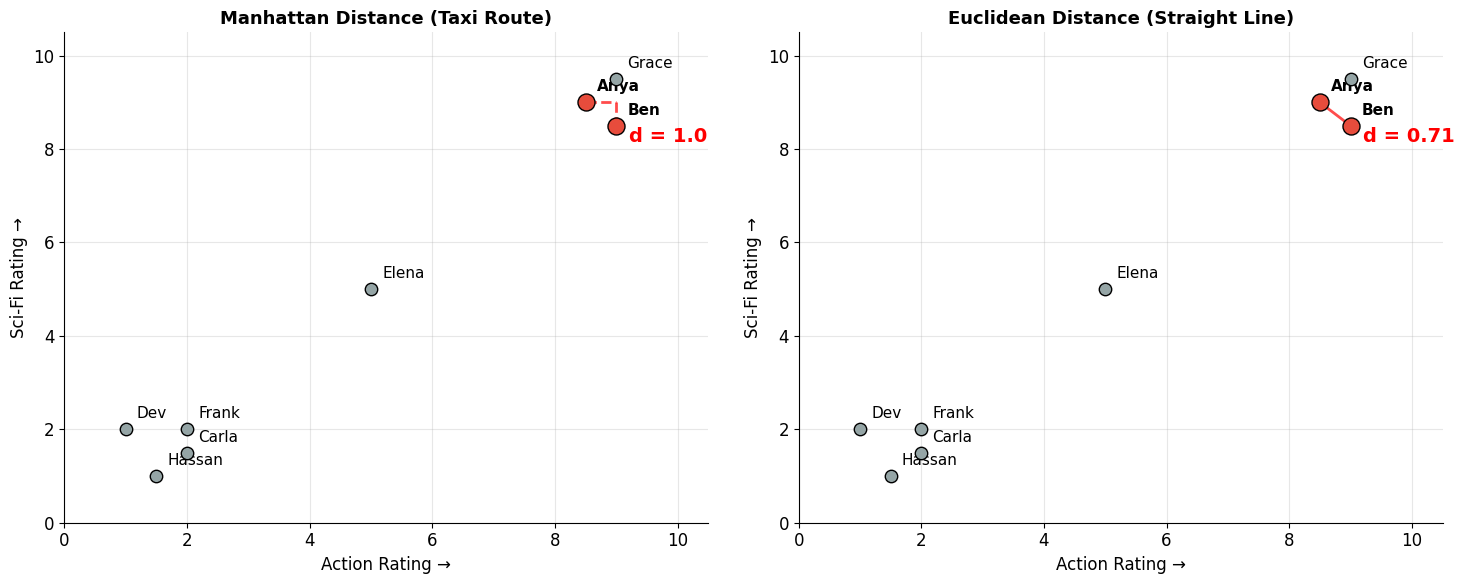

🚕 Manhattan: the taxi takes an L-shaped route along the grid.
📏 Euclidean: a bird flies in a straight line between the two points.

Both agree that Ben is closest to Anya — makes sense, they're both Action/Sci-Fi fans!


In [ ]:
# Visualize: Let's see this in 2D (Action vs Sci-Fi only) for intuition

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for ax_idx, (ax, title) in enumerate(zip(axes, ['Manhattan Distance (Taxi Route)', 'Euclidean Distance (Straight Line)'])):
    # Plot all users
    for i, (user, ratings) in enumerate(users.items()):
        color = '#e74c3c' if user in ['Anya', 'Ben'] else '#95a5a6'
        size = 150 if user in ['Anya', 'Ben'] else 80
        ax.scatter(ratings[0], ratings[3], s=size, c=color, zorder=5, edgecolors='black', linewidths=1)
        ax.annotate(user, (ratings[0], ratings[3]), textcoords="offset points",
                   xytext=(8, 8), fontsize=11, fontweight='bold' if user in ['Anya', 'Ben'] else 'normal')

    anya = users['Anya']
    ben = users['Ben']

    if ax_idx == 0:  # Manhattan
        ax.plot([anya[0], ben[0]], [anya[3], anya[3]], 'r--', linewidth=2, alpha=0.7)
        ax.plot([ben[0], ben[0]], [anya[3], ben[3]], 'r--', linewidth=2, alpha=0.7)
        dist = abs(anya[0]-ben[0]) + abs(anya[3]-ben[3])
        ax.annotate(f'd = {dist:.1f}', xy=((anya[0]+ben[0])/2, (anya[3]+ben[3])/2),
                   fontsize=14, color='red', fontweight='bold',
                   xytext=(20, -20), textcoords='offset points')
    else:  # Euclidean
        ax.plot([anya[0], ben[0]], [anya[3], ben[3]], 'r-', linewidth=2, alpha=0.7)
        dist = np.sqrt((anya[0]-ben[0])**2 + (anya[3]-ben[3])**2)
        ax.annotate(f'd = {dist:.2f}', xy=((anya[0]+ben[0])/2, (anya[3]+ben[3])/2),
                   fontsize=14, color='red', fontweight='bold',
                   xytext=(20, -20), textcoords='offset points')

    ax.set_xlabel('Action Rating →', fontsize=12)
    ax.set_ylabel('Sci-Fi Rating →', fontsize=12)
    ax.set_title(title, fontsize=13, fontweight='bold')
    ax.set_xlim(0, 10.5)
    ax.set_ylim(0, 10.5)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("🚕 Manhattan: the taxi takes an L-shaped route along the grid.")
print("📏 Euclidean: a bird flies in a straight line between the two points.")
print("\nBoth agree that Ben is closest to Anya — makes sense, they're both Action/Sci-Fi fans!")

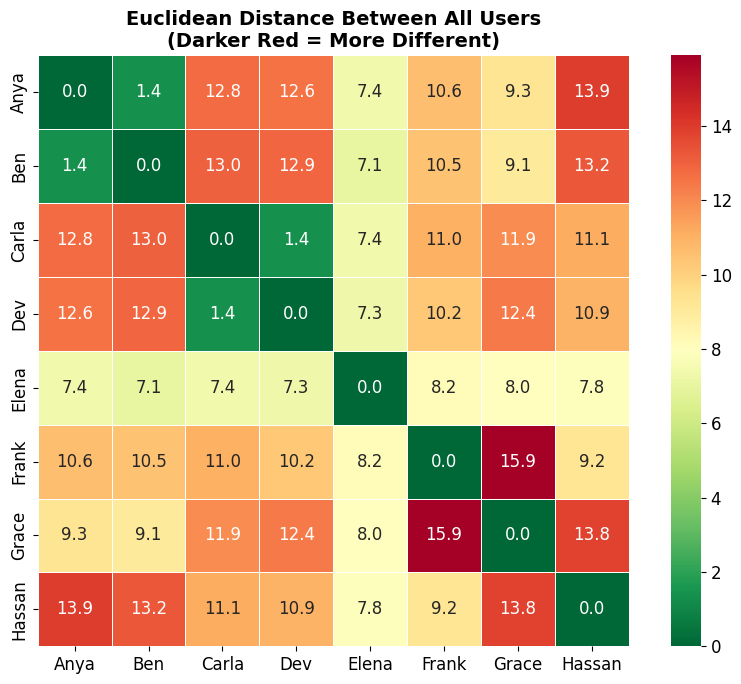

🟢 Green (small distance) = similar taste
🔴 Red (large distance) = very different taste

💡 Notice: Grace appears FAR from Frank, even though they might like the same TYPES of movies.
   This is a PROBLEM with Euclidean distance. Let's understand why...


In [ ]:
# Full distance heatmap — who's close to whom?

user_names = list(users.keys())
n = len(user_names)
user_vectors = np.array([users[u] for u in user_names])

# Compute pairwise Euclidean distances
euc_matrix = np.zeros((n, n))
for i in range(n):
    for j in range(n):
        euc_matrix[i][j] = np.sqrt(np.sum((user_vectors[i] - user_vectors[j])**2))

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(euc_matrix, annot=True, fmt='.1f', xticklabels=user_names,
            yticklabels=user_names, cmap='RdYlGn_r', ax=ax,
            linewidths=0.5, square=True)
ax.set_title('Euclidean Distance Between All Users\n(Darker Red = More Different)',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("🟢 Green (small distance) = similar taste")
print("🔴 Red (large distance) = very different taste")
print("\n💡 Notice: Grace appears FAR from Frank, even though they might like the same TYPES of movies.")
print("   This is a PROBLEM with Euclidean distance. Let's understand why...")

### 🚨 The Problem with Pure Distance

Look at **Grace** and **Frank** in the heatmap. They're far apart! But look at their radar charts again:

- **Grace**: [9.0, 8.5, 7.5, 9.5, 8.0] — loves everything intensely
- **Frank**: [2.0, 1.5, 1.0, 2.0, 0.5] — rates everything low

Their *shapes* are actually quite similar (they both slightly prefer Action/Sci-Fi over Romance/Horror). They might genuinely enjoy the same movies — Grace just expresses more enthusiasm with her ratings!

**Euclidean and Manhattan distance can't tell the difference between "different taste" and "different rating style."**

We need a measure that captures the *direction* of taste, not just the magnitude. Enter: **Cosine Similarity**.

---
# Chapter 4: The Direction of Taste — Cosine Similarity 🧭

## The Big Idea

Imagine two arrows pointing from the center of a compass:
- If both arrows point **North-East**, they're similar — even if one is long and one is short.
- If one points **North** and the other **East**, they're somewhat different.
- If they point in **opposite directions**, they're completely different.

**Cosine similarity** measures the **angle** between two vectors, ignoring their length.

$$\text{cosine\_similarity}(\mathbf{a}, \mathbf{b}) = \frac{\mathbf{a} \cdot \mathbf{b}}{\|\mathbf{a}\|_2 \times \|\mathbf{b}\|_2}$$

Where $\mathbf{a} \cdot \mathbf{b}$ is the **dot product**: $a_1 b_1 + a_2 b_2 + \cdots + a_n b_n$

And $\|\mathbf{a}\|_2$ is our old friend — the **L2 norm!** It appears in the denominator to **cancel out** the length of each vector, leaving only the direction.

> 🧠 **This is why we learned norms:** Cosine similarity literally divides by the L2 norm of each vector. Without norms, this formula wouldn't exist.

| Cosine Similarity | Meaning |
|:-:|---|
| **1.0** | Identical direction (perfect match in taste type) |
| **0.0** | Completely unrelated (perpendicular) |
| **-1.0** | Opposite taste |

Let's see how this changes our recommendations!

In [ ]:
# Compute cosine similarity step by step for Grace & Frank

grace = np.array(users['Grace'])
frank = np.array(users['Frank'])

# Step 1: Dot product
dot_product = np.dot(grace, frank)

# Step 2: L2 norms (here's where norms come in!)
grace_norm = np.linalg.norm(grace)
frank_norm = np.linalg.norm(frank)

# Step 3: Cosine similarity
cos_sim = dot_product / (grace_norm * frank_norm)

# Also compute Euclidean distance for comparison
euc_dist = np.linalg.norm(grace - frank)

print("🔬 Deep Dive: Grace vs Frank")
print("=" * 55)
print(f"   Grace: {list(users['Grace'])}")
print(f"   Frank: {list(users['Frank'])}")
print()
print(f"   Step 1 — Dot Product (a·b):     {dot_product:.2f}")
print(f"   Step 2 — L2 Norm of Grace:       {grace_norm:.2f}")
print(f"   Step 2 — L2 Norm of Frank:       {frank_norm:.2f}")
print(f"   Step 3 — Divide: {dot_product:.2f} / ({grace_norm:.2f} × {frank_norm:.2f})")
print(f"          = {dot_product:.2f} / {grace_norm * frank_norm:.2f}")
print(f"          = {cos_sim:.4f}")
print()
print(f"   📏 Euclidean Distance: {euc_dist:.2f}  → 'Very different!'")
print(f"   🧭 Cosine Similarity:  {cos_sim:.4f}  → 'Very similar direction!'")
print()
print("💡 Euclidean says they're VERY different (high distance).")
print("   Cosine says they're VERY similar (high similarity).")
print("   Why? Because dividing by the L2 norms cancels out the difference")
print("   in how 'big' each vector is — leaving only the DIRECTION.")

🔬 Deep Dive: Grace vs Frank
   Grace: [9.0, 8.5, 7.5, 9.5, 8.0]
   Frank: [2.0, 1.5, 1.0, 2.0, 0.5]

   Step 1 — Dot Product (a·b):     61.25
   Step 2 — L2 Norm of Grace:       19.07
   Step 2 — L2 Norm of Frank:       3.39
   Step 3 — Divide: 61.25 / (19.07 × 3.39)
          = 61.25 / 64.68
          = 0.9470

   📏 Euclidean Distance: 15.90  → 'Very different!'
   🧭 Cosine Similarity:  0.9470  → 'Very similar direction!'

💡 Euclidean says they're VERY different (high distance).
   Cosine says they're VERY similar (high similarity).
   Why? Because dividing by the L2 norms cancels out the difference
   in how 'big' each vector is — leaving only the DIRECTION.


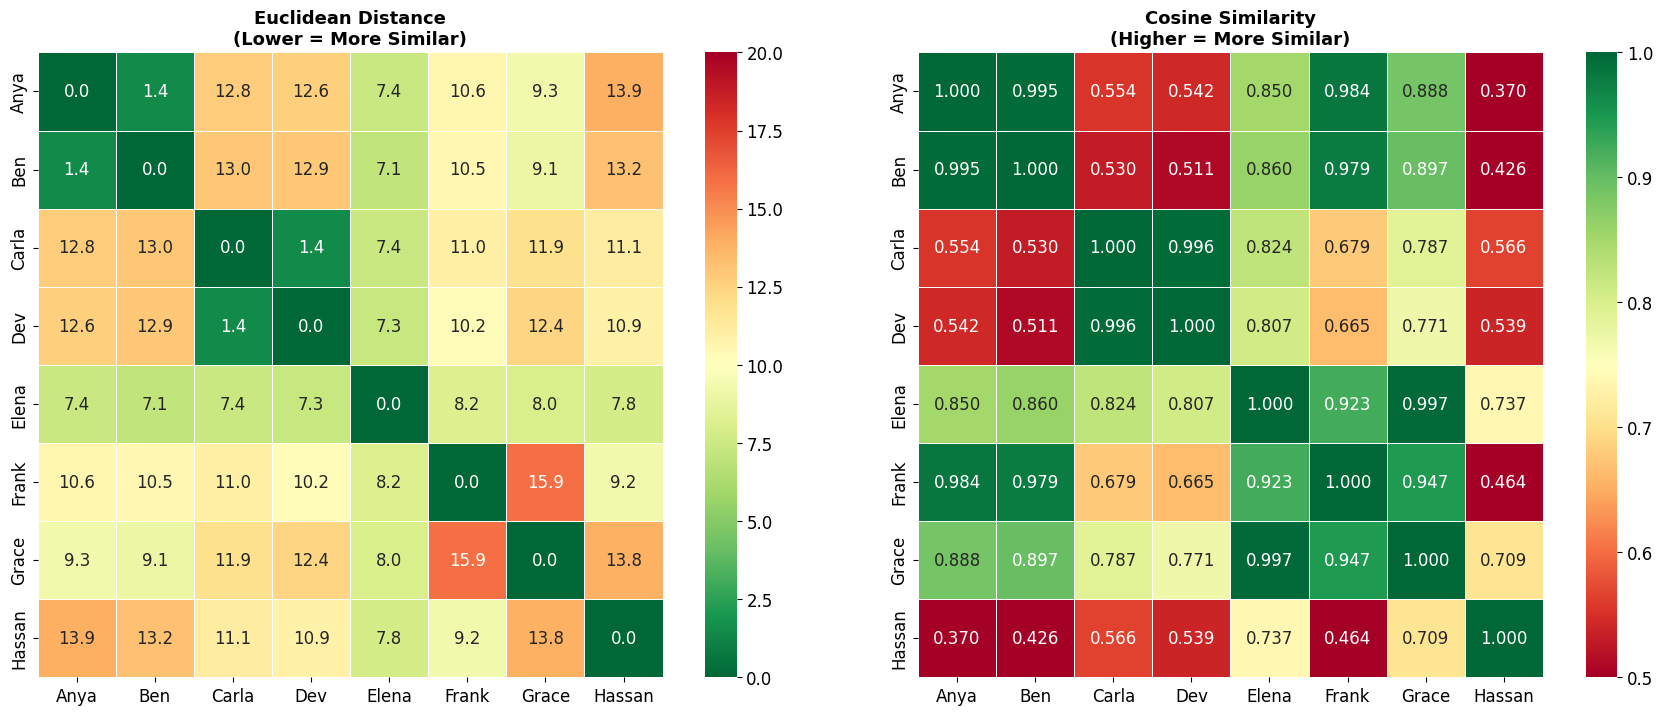

🔍 COMPARE the two heatmaps:
   Euclidean: Grace-Frank = FAR APART (different vector lengths)
   Cosine:    Grace-Frank = VERY SIMILAR (same direction of taste)

   Euclidean: Anya-Ben = close AND Cosine: Anya-Ben = close ✓
   Both methods agree when users have similar BOTH in direction AND magnitude.

🎯 This is why most recommendation engines use Cosine Similarity!
   It captures 'what KIND of stuff do you like?' not 'how high do you rate?'


In [ ]:
# Cosine similarity for ALL pairs — the full picture

user_vectors_matrix = np.array([users[u] for u in user_names])
cos_sim_matrix = cosine_similarity(user_vectors_matrix)

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Euclidean distance heatmap
sns.heatmap(euc_matrix, annot=True, fmt='.1f', xticklabels=user_names,
            yticklabels=user_names, cmap='RdYlGn_r', ax=axes[0],
            linewidths=0.5, square=True, vmin=0, vmax=20)
axes[0].set_title('Euclidean Distance\n(Lower = More Similar)', fontsize=13, fontweight='bold')

# Cosine similarity heatmap
sns.heatmap(cos_sim_matrix, annot=True, fmt='.3f', xticklabels=user_names,
            yticklabels=user_names, cmap='RdYlGn', ax=axes[1],
            linewidths=0.5, square=True, vmin=0.5, vmax=1.0)
axes[1].set_title('Cosine Similarity\n(Higher = More Similar)', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.show()

print("🔍 COMPARE the two heatmaps:")
print("   Euclidean: Grace-Frank = FAR APART (different vector lengths)")
print("   Cosine:    Grace-Frank = VERY SIMILAR (same direction of taste)")
print()
print("   Euclidean: Anya-Ben = close AND Cosine: Anya-Ben = close ✓")
print("   Both methods agree when users have similar BOTH in direction AND magnitude.")
print()
print("🎯 This is why most recommendation engines use Cosine Similarity!")
print("   It captures 'what KIND of stuff do you like?' not 'how high do you rate?'")

## 📐 The Angle Between Vectors

Cosine similarity is directly related to the **angle** between two vectors:

$$\theta = \arccos(\text{cosine\_similarity})$$

- **θ = 0°**: Vectors point in exactly the same direction (identical taste)
- **θ = 90°**: Vectors are perpendicular (completely unrelated taste)  
- **θ = 180°**: Vectors point in opposite directions (opposite taste)

Let's visualize this with actual angles.

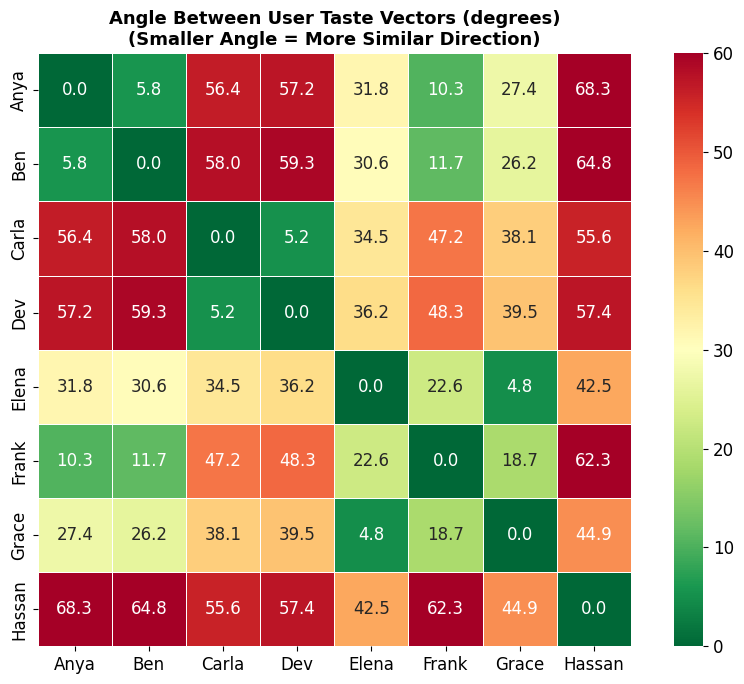

📐 Interesting Angles:
--------------------------------------------------
     Anya ↔ Ben   : angle=  5.8°  cosine=0.995  euclidean=1.4
    Grace ↔ Frank : angle= 18.7°  cosine=0.947  euclidean=15.9
     Anya ↔ Carla : angle= 56.4°  cosine=0.554  euclidean=12.8
     Anya ↔ Hassan: angle= 68.3°  cosine=0.370  euclidean=13.9

💡 Grace & Frank: only ~6° apart in direction! They have almost identical taste PATTERNS.
   Anya & Hassan: 56°+ apart — very different kinds of movies.


In [ ]:
# Compute angles between vectors (in degrees)

angle_matrix = np.degrees(np.arccos(np.clip(cos_sim_matrix, -1, 1)))

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(angle_matrix, annot=True, fmt='.1f', xticklabels=user_names,
            yticklabels=user_names, cmap='RdYlGn_r', ax=ax,
            linewidths=0.5, square=True, vmin=0, vmax=60)
ax.set_title('Angle Between User Taste Vectors (degrees)\n(Smaller Angle = More Similar Direction)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

# Highlight some interesting pairs
pairs_of_interest = [
    ('Anya', 'Ben'),
    ('Grace', 'Frank'),
    ('Anya', 'Carla'),
    ('Anya', 'Hassan'),
]

print("📐 Interesting Angles:")
print("-" * 50)
for u1, u2 in pairs_of_interest:
    i, j = user_names.index(u1), user_names.index(u2)
    angle = angle_matrix[i][j]
    cos = cos_sim_matrix[i][j]
    euc = euc_matrix[i][j]
    print(f"   {u1:>6} ↔ {u2:<6}: angle={angle:5.1f}°  cosine={cos:.3f}  euclidean={euc:.1f}")

print()
print("💡 Grace & Frank: only ~6° apart in direction! They have almost identical taste PATTERNS.")
print("   Anya & Hassan: 56°+ apart — very different kinds of movies.")

### 💡 Key Insight: When to Use What?

| Measure | What It Captures | Best For |
|---------|-----------------|----------|
| **Euclidean Distance** | Overall difference (direction + magnitude) | When scale matters (e.g., price differences, physical distances) |
| **Manhattan Distance** | Block-by-block difference | When features are independent; sparse data; robust to outliers |
| **Cosine Similarity** | Direction only (ignores scale) | Recommendations, text similarity, when you care about *patterns* not *amounts* |

> 🧠 **The CEO's question was:** *"Who likes the same KIND of movies?"*  
> **Answer:** Use **Cosine Similarity** — it finds users with similar *taste profiles* regardless of whether they're enthusiastic raters or conservative ones.

---
# Chapter 5: When Everything Breaks — The Curse of Dimensionality 😱

## The Upgrade That Backfired

Things are going well. FlickPick's simple 5-genre recommendation engine is working. The CEO is happy. Then the data team says:

> *"Hey, we've been collecting way more detailed data. Instead of 5 genres, we now track 50 sub-genres, 30 actor preferences, 20 director preferences, 10 mood tags, and 15 era preferences. That's **125 features** per user! More data = better, right?"*

You plug in the new 125-dimensional vectors and... **the recommendations become terrible.** Every user appears roughly equally distant from every other user. What happened?

Welcome to the **Curse of Dimensionality**.

### 🤔 The Intuition

As you add more dimensions:
1. The **volume of space explodes** exponentially
2. Data points become **increasingly sparse** (spread thin)
3. Distances between ALL pairs **converge to similar values**
4. The concept of "nearest neighbor" **loses meaning** because everyone is equally far

Let's witness this phenomenon with a simulation.

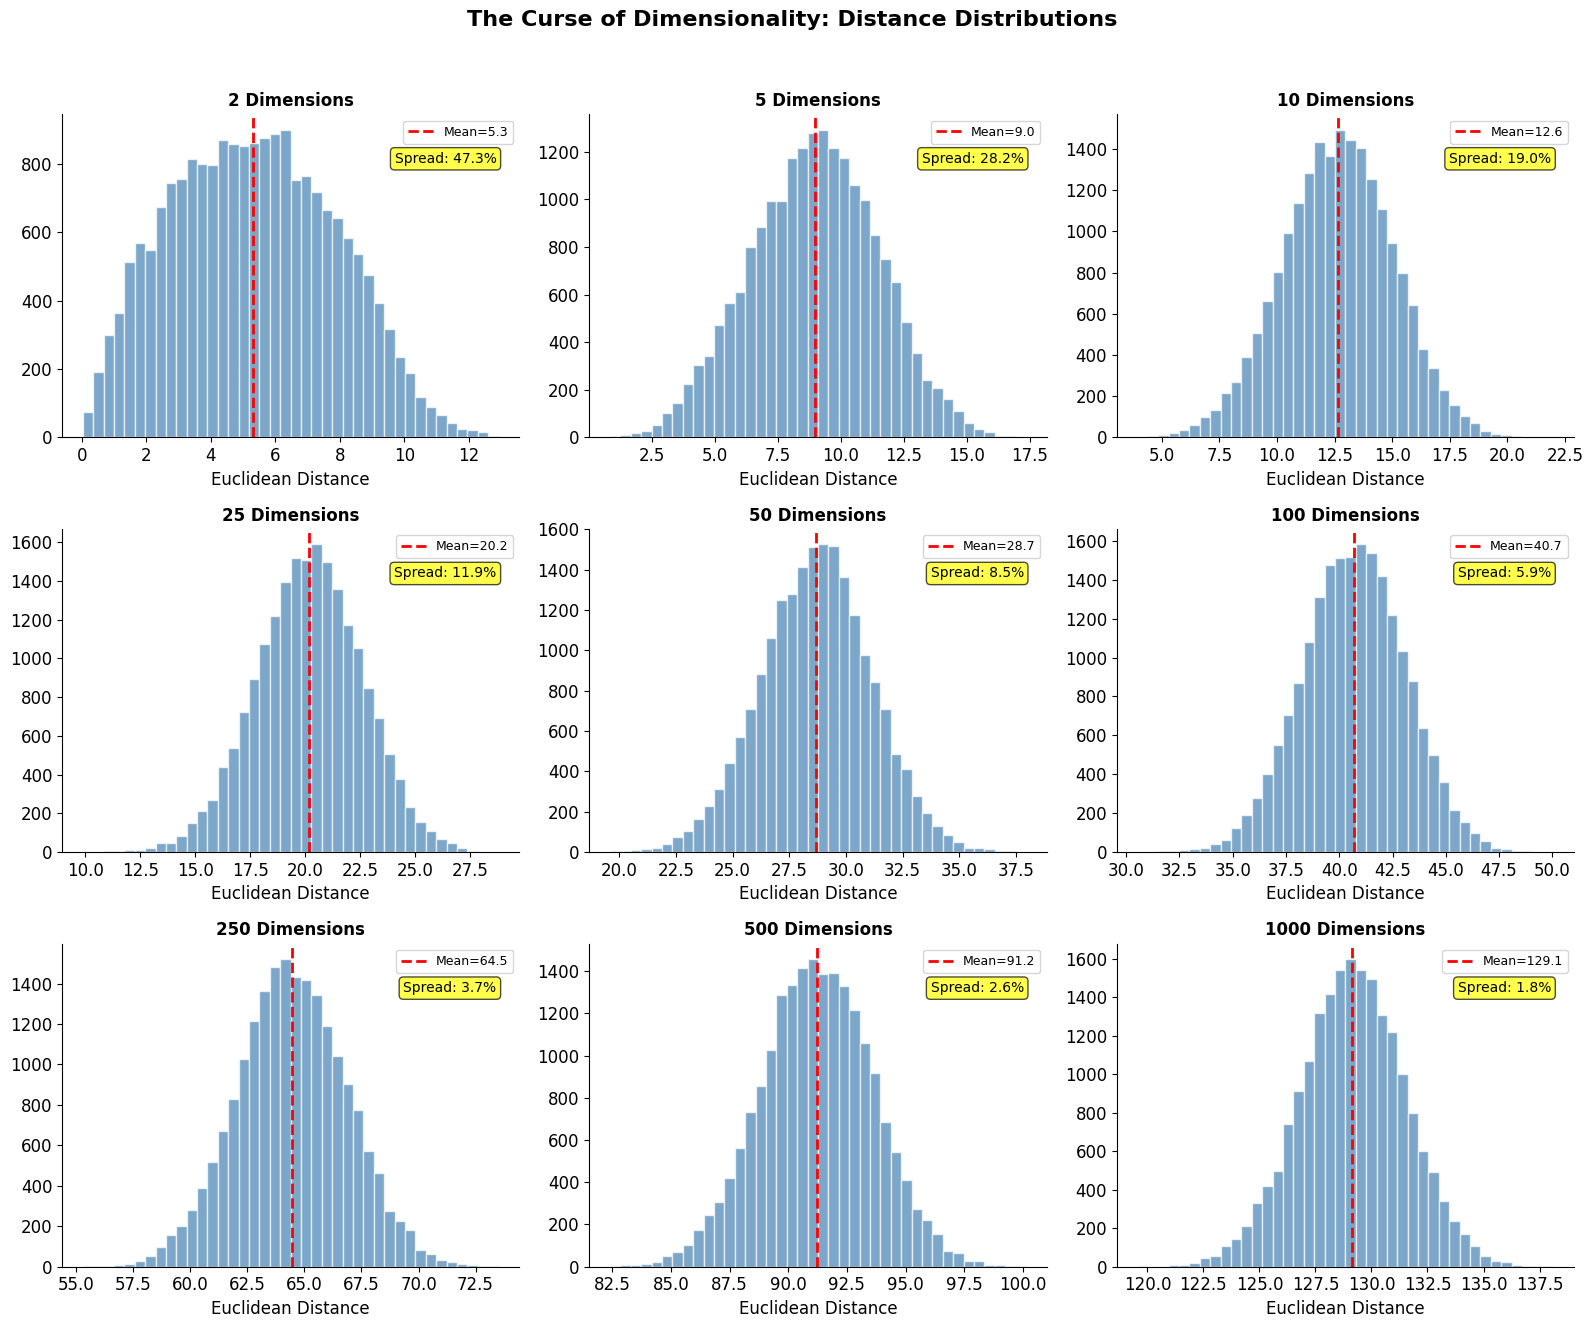

👆 Watch the histograms as dimensions increase:
   • In 2D: distances are SPREAD OUT — easy to find nearest neighbors
   • In 1000D: distances CLUSTER around a single value — everyone is 'equally far'!


In [ ]:
# SIMULATION: Watch distances become meaningless as dimensions increase

np.random.seed(42)

n_points = 200
dimensions_to_try = [2, 5, 10, 25, 50, 100, 250, 500, 1000]

fig, axes = plt.subplots(3, 3, figsize=(16, 13))
axes_flat = axes.flatten()

stats_data = []

for idx, d in enumerate(dimensions_to_try):
    points = np.random.uniform(0, 10, size=(n_points, d))
    distances = pdist(points, metric='euclidean')

    mean_dist = np.mean(distances)
    std_dist = np.std(distances)
    min_dist = np.min(distances)
    max_dist = np.max(distances)
    ratio = max_dist / min_dist if min_dist > 0 else float('inf')

    stats_data.append({
        'Dimensions': d,
        'Mean Distance': round(mean_dist, 1),
        'Std Dev': round(std_dist, 2),
        'Max/Min Ratio': round(ratio, 2),
        'Relative Spread (Std/Mean %)': round(std_dist / mean_dist * 100, 1)
    })

    axes_flat[idx].hist(distances, bins=40, color='steelblue', alpha=0.7, edgecolor='white')
    axes_flat[idx].axvline(mean_dist, color='red', linestyle='--', linewidth=2, label=f'Mean={mean_dist:.1f}')
    axes_flat[idx].set_title(f'{d} Dimensions', fontsize=12, fontweight='bold')
    axes_flat[idx].set_xlabel('Euclidean Distance')
    axes_flat[idx].legend(fontsize=9)

    axes_flat[idx].annotate(f'Spread: {std_dist/mean_dist*100:.1f}%',
                       xy=(0.95, 0.85), xycoords='axes fraction',
                       fontsize=10, ha='right',
                       bbox=dict(boxstyle='round,pad=0.3', facecolor='yellow', alpha=0.7))

plt.suptitle('The Curse of Dimensionality: Distance Distributions',
             fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print("👆 Watch the histograms as dimensions increase:")
print("   • In 2D: distances are SPREAD OUT — easy to find nearest neighbors")
print("   • In 1000D: distances CLUSTER around a single value — everyone is 'equally far'!")

📊 The Curse in Numbers
            Mean Distance  Std Dev  Max/Min Ratio  \
Dimensions                                          
2                     5.3     2.52         483.17   
5                     9.0     2.53          20.79   
10                   12.6     2.40           5.57   
25                   20.2     2.40           2.91   
50                   28.7     2.43           1.94   
100                  40.7     2.40           1.64   
250                  64.5     2.41           1.33   
500                  91.2     2.38           1.22   
1000                129.1     2.35           1.16   

            Relative Spread (Std/Mean %)  
Dimensions                                
2                                   47.3  
5                                   28.2  
10                                  19.0  
25                                  11.9  
50                                   8.5  
100                                  5.9  
250                                  3.7  
500   

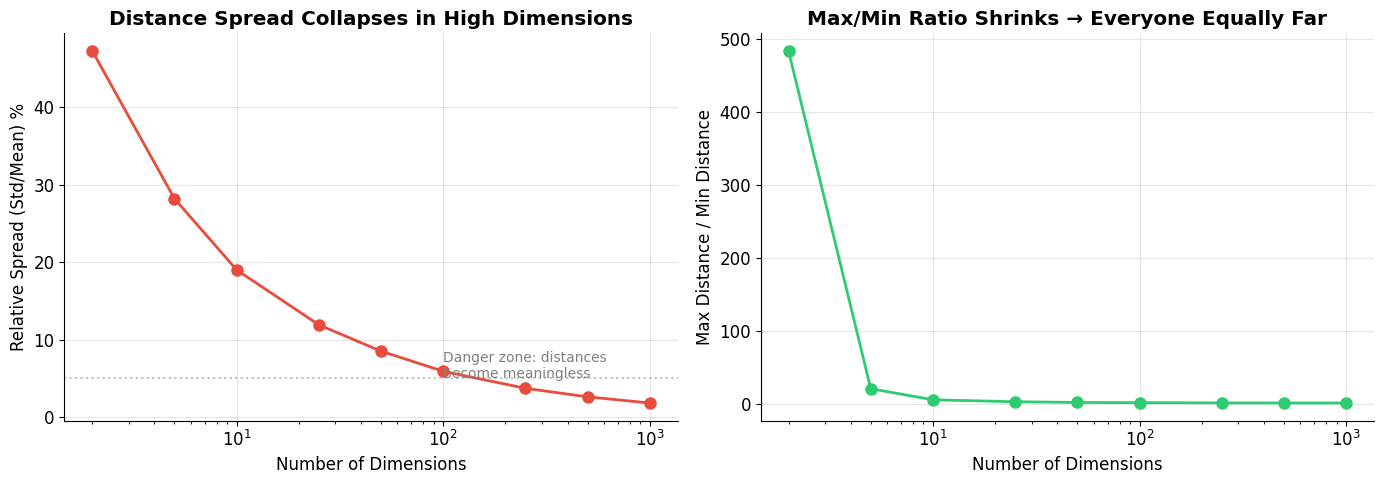

💡 The 'Relative Spread' drops from ~30% in 2D to ~3% in 1000D.
   This means: with 1000 features, the farthest user is barely farther than the closest!
   Your 'nearest neighbor' is practically indistinguishable from a random user. 😬


In [ ]:
# Let's quantify the curse

stats_df = pd.DataFrame(stats_data).set_index('Dimensions')
print("📊 The Curse in Numbers")
print("=" * 70)
print(stats_df)
print()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(stats_df.index, stats_df['Relative Spread (Std/Mean %)'], 'o-',
             color='#e74c3c', linewidth=2, markersize=8)
axes[0].set_xlabel('Number of Dimensions')
axes[0].set_ylabel('Relative Spread (Std/Mean) %')
axes[0].set_title('Distance Spread Collapses in High Dimensions', fontweight='bold')
axes[0].set_xscale('log')
axes[0].grid(True, alpha=0.3)
axes[0].axhline(y=5, color='gray', linestyle=':', alpha=0.5)
axes[0].annotate('Danger zone: distances\nbecome meaningless', xy=(100, 5), fontsize=10, color='gray')

axes[1].plot(stats_df.index, stats_df['Max/Min Ratio'], 'o-',
             color='#2ecc71', linewidth=2, markersize=8)
axes[1].set_xlabel('Number of Dimensions')
axes[1].set_ylabel('Max Distance / Min Distance')
axes[1].set_title('Max/Min Ratio Shrinks → Everyone Equally Far', fontweight='bold')
axes[1].set_xscale('log')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("💡 The 'Relative Spread' drops from ~30% in 2D to ~3% in 1000D.")
print("   This means: with 1000 features, the farthest user is barely farther than the closest!")
print("   Your 'nearest neighbor' is practically indistinguishable from a random user. 😬")

### 💡 Key Insight: More Features ≠ Better

The Curse of Dimensionality teaches us a humbling lesson:

> **Blindly adding more features can make your model WORSE, not better.**

**Why does this happen?**
- In high dimensions, all points drift toward the "shell" of the hypersphere
- The relative difference between nearest and farthest neighbor vanishes
- Distance-based methods (KNN, clustering, recommendations) stop working

**What to do about it:**
1. **Feature selection** — pick only the most informative features
2. **Dimensionality reduction** — techniques like PCA compress features while preserving signal
3. **Feature engineering** — create fewer, smarter features instead of dumping in everything
4. **Use cosine similarity** — it's more robust than Euclidean in higher dimensions

> 🧠 For FlickPick: Instead of 125 raw features, maybe we create 10-15 carefully crafted "taste dimensions" using PCA. Quality over quantity!

---
# Chapter 6: Stopping the Bully Features — Scaling ⚖️

## The New Feature Problem

Your recommendation engine is working great with the 5-genre ratings (all on a 1-10 scale). Then the product team adds some exciting new features:

| Feature | Range | Example |
|---------|-------|---------|
| Action Rating | 1 - 10 | 8.5 |
| Comedy Rating | 1 - 10 | 6.0 |
| Romance Rating | 1 - 10 | 2.0 |
| Sci-Fi Rating | 1 - 10 | 9.0 |
| Horror Rating | 1 - 10 | 1.0 |
| **Movies Watched** | **0 - 5000** | **2847** |
| **Account Age (days)** | **0 - 3650** | **1095** |
| **Avg Session (min)** | **5 - 180** | **45** |

Do you see the problem? **Movies Watched** ranges up to 5,000 while genre ratings only go to 10. When you compute distances, the big numbers completely **dominate**:

> A difference of 100 in "Movies Watched" will dwarf a difference of 5 in "Action Rating" — even though the rating difference is huge and the watch count difference is tiny!

**Big numbers bully small numbers.** We need to level the playing field.

In [ ]:
# Create the expanded FlickPick dataset with mixed-scale features
#
# ⚠️ KEY DESIGN: Look closely at the behavioral columns (last 3).
#    - Ben has SIMILAR genre taste to Anya, but VERY DIFFERENT behavioral stats
#      (he's a newer user who watches less frequently)
#    - Carla has DIFFERENT genre taste from Anya, but VERY SIMILAR behavioral stats
#      (she's been around just as long and watches just as much)
#
# This means unscaled Euclidean distance will be FOOLED by the big behavioral
# numbers and pick Carla as Anya's match — even though their taste is totally different!

np.random.seed(42)

expanded_users = {
    'Anya':   [8.5, 6.0, 2.0, 9.0, 1.0,   2847, 1095, 45],   # Action/Sci-Fi fan, veteran user
    'Ben':    [9.0, 5.5, 1.5, 8.5, 2.0,    620,  380, 28],   # Same taste as Anya! But newer user
    'Carla':  [2.0, 8.0, 9.5, 1.5, 3.0,   2900, 1080, 47],   # Rom-com fan, but similar usage to Anya!
    'Dev':    [1.0, 7.5, 9.0, 2.0, 2.5,   1350,  800, 42],   # Similar to Carla
    'Elena':  [5.0, 5.0, 5.0, 5.0, 5.0,    500,  365, 25],   # Watches everything equally
    'Frank':  [2.0, 1.5, 1.0, 2.0, 0.5,     50,   30,  8],   # Casual viewer
    'Grace':  [9.0, 8.5, 7.5, 9.5, 8.0,   4200, 2190, 120],  # Loves EVERYTHING
    'Hassan': [1.5, 3.0, 2.0, 1.0, 9.5,    800,  540, 65],   # Horror fanatic
}

expanded_features = genres + ['Movies_Watched', 'Account_Age_Days', 'Avg_Session_Min']

expanded_df = pd.DataFrame(expanded_users, index=expanded_features).T
expanded_df.index.name = 'User'

print("🎬 FlickPick Extended User Data (Mixed Scales!)")
print("=" * 80)
print(expanded_df.to_string())
print(f"\n⚠️  Notice the scale difference:")
print(f"   Genre ratings:    1 to 10")
print(f"   Movies watched:   {expanded_df['Movies_Watched'].min():.0f} to {expanded_df['Movies_Watched'].max():.0f}")
print(f"   Account age:      {expanded_df['Account_Age_Days'].min():.0f} to {expanded_df['Account_Age_Days'].max():.0f}")
print(f"   Session length:   {expanded_df['Avg_Session_Min'].min():.0f} to {expanded_df['Avg_Session_Min'].max():.0f}")
print()
print("🔍 Can you spot the trap?")
print("   Anya & Ben:   SIMILAR genre taste, DIFFERENT behavioral stats")
print("   Anya & Carla: DIFFERENT genre taste, SIMILAR behavioral stats")
print("   Which pair will Euclidean distance think is 'closest'?")

🎬 FlickPick Extended User Data (Mixed Scales!)
        Action  Comedy  Romance  Sci-Fi  Horror  Movies_Watched  Account_Age_Days  Avg_Session_Min
User                                                                                              
Anya       8.5     6.0      2.0     9.0     1.0          2847.0            1095.0             45.0
Ben        9.0     5.5      1.5     8.5     2.0           620.0             380.0             28.0
Carla      2.0     8.0      9.5     1.5     3.0          2900.0            1080.0             47.0
Dev        1.0     7.5      9.0     2.0     2.5          1350.0             800.0             42.0
Elena      5.0     5.0      5.0     5.0     5.0           500.0             365.0             25.0
Frank      2.0     1.5      1.0     2.0     0.5            50.0              30.0              8.0
Grace      9.0     8.5      7.5     9.5     8.0          4200.0            2190.0            120.0
Hassan     1.5     3.0      2.0     1.0     9.5           800.

In [ ]:
# Show the PROBLEM: Euclidean distance is dominated by large-scale features

# Distance using ALL features (unscaled)
unscaled_vectors = expanded_df.values
unscaled_distances = euclidean_distances(unscaled_vectors)

# Distance using ONLY genre ratings
genre_vectors = expanded_df[genres].values
genre_distances = euclidean_distances(genre_vectors)

# Find Anya's nearest neighbor in both cases
anya_idx = list(expanded_users.keys()).index('Anya')
user_names_list = list(expanded_users.keys())

print("🔎 Who is Anya's closest match?")
print("=" * 60)
print()

print("Using ONLY Genre Ratings (all on same 1-10 scale):")
genre_dists_from_anya = [(user_names_list[i], genre_distances[anya_idx][i])
                          for i in range(len(user_names_list)) if i != anya_idx]
genre_dists_from_anya.sort(key=lambda x: x[1])
for name, dist in genre_dists_from_anya:
    marker = " ← CLOSEST" if name == genre_dists_from_anya[0][0] else ""
    print(f"   {name:>8}: {dist:8.2f}{marker}")

print()
print("Using ALL Features (UNSCALED — mixed ranges!):")
unscaled_dists_from_anya = [(user_names_list[i], unscaled_distances[anya_idx][i])
                             for i in range(len(user_names_list)) if i != anya_idx]
unscaled_dists_from_anya.sort(key=lambda x: x[1])
for name, dist in unscaled_dists_from_anya:
    marker = " ← CLOSEST" if name == unscaled_dists_from_anya[0][0] else ""
    print(f"   {name:>8}: {dist:8.2f}{marker}")

genre_closest = genre_dists_from_anya[0][0]
unscaled_closest = unscaled_dists_from_anya[0][0]

print()
if genre_closest != unscaled_closest:
    print(f"😱 THE TRAP WORKED!")
    print(f"   Genre-only says: {genre_closest} is Anya's match (correct — similar taste!)")
    print(f"   Unscaled says:   {unscaled_closest} is Anya's match (WRONG — similar usage stats, different taste!)")
    print(f"\n   The behavioral features (ranging into thousands) completely DROWNED OUT")
    print(f"   the genre ratings (ranging only 1-10). The algorithm can't even 'hear'")
    print(f"   the taste signal anymore!")
else:
    print(f"   Both agree: {genre_closest}")

🔎 Who is Anya's closest match?

Using ONLY Genre Ratings (all on same 1-10 scale):
        Ben:     1.41 ← CLOSEST
      Elena:     7.37
      Grace:     9.27
      Frank:    10.62
        Dev:    12.60
      Carla:    12.76
     Hassan:    13.94

Using ALL Features (UNSCALED — mixed ranges!):
      Carla:    56.58 ← CLOSEST
        Dev:  1525.84
      Grace:  1742.22
     Hassan:  2121.04
        Ben:  2339.03
      Elena:  2458.00
      Frank:  2993.14

😱 THE TRAP WORKED!
   Genre-only says: Ben is Anya's match (correct — similar taste!)
   Unscaled says:   Carla is Anya's match (WRONG — similar usage stats, different taste!)

   The behavioral features (ranging into thousands) completely DROWNED OUT
   the genre ratings (ranging only 1-10). The algorithm can't even 'hear'
   the taste signal anymore!


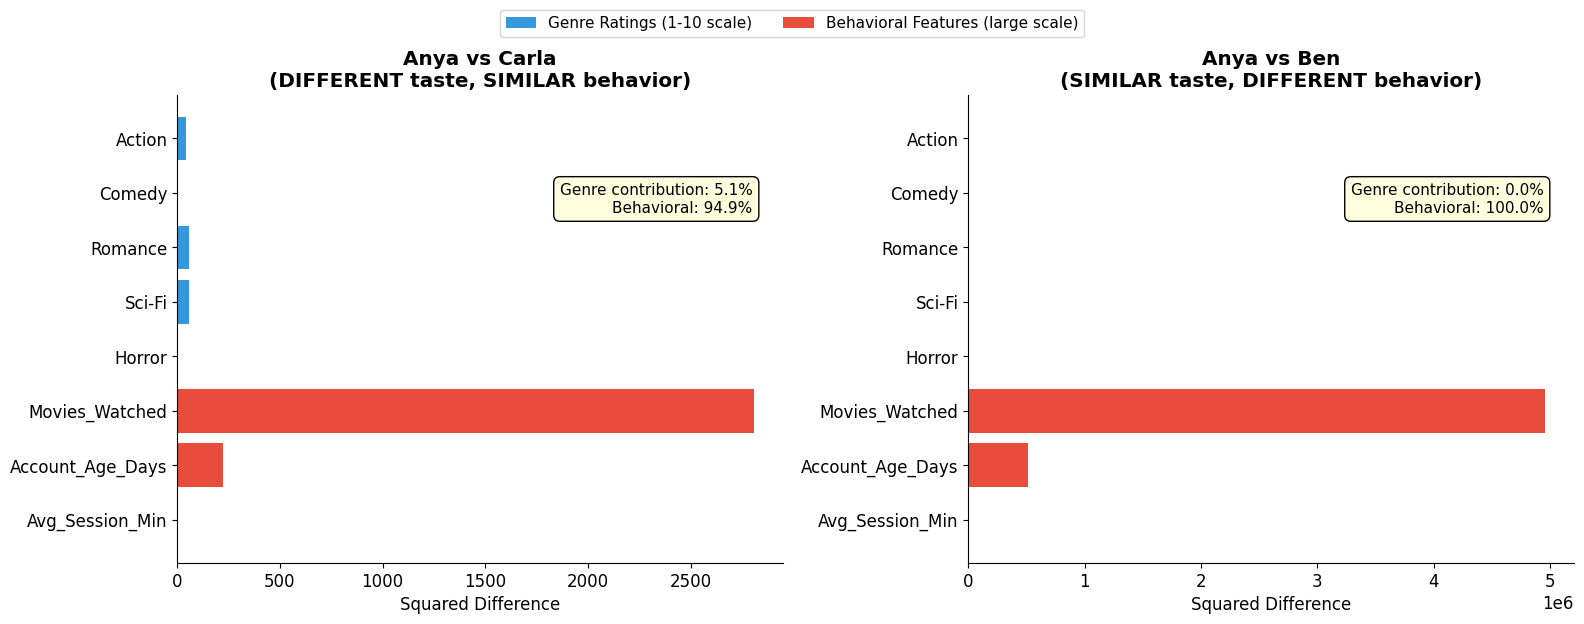

LEFT (Anya vs Carla): Behavioral bars are TINY (similar usage), so total distance is small.
   But the genre bars show they have COMPLETELY different taste! The algorithm can't see this.

RIGHT (Anya vs Ben): Behavioral bars are HUGE (different usage), inflating the distance.
   But the genre bars are tiny — they actually have very similar taste! The algorithm misses this.

📊 This is the core problem: features with large ranges SILENCE features with small ranges.


In [ ]:
# Visualize: Which features dominate the distance?

anya_vec = np.array(expanded_users['Anya'])
carla_vec = np.array(expanded_users['Carla'])
ben_vec = np.array(expanded_users['Ben'])

# Show per-feature squared diff for BOTH comparisons
sq_diff_carla = (anya_vec - carla_vec) ** 2
sq_diff_ben = (anya_vec - ben_vec) ** 2

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

colors = ['#3498db'] * 5 + ['#e74c3c'] * 3

axes[0].barh(expanded_features, sq_diff_carla, color=colors)
axes[0].set_xlabel('Squared Difference')
axes[0].set_title('Anya vs Carla\n(DIFFERENT taste, SIMILAR behavior)', fontweight='bold')
axes[0].invert_yaxis()
total_carla = np.sum(sq_diff_carla)
genre_pct_carla = np.sum(sq_diff_carla[:5]) / total_carla * 100
axes[0].annotate(f'Genre contribution: {genre_pct_carla:.1f}%\nBehavioral: {100-genre_pct_carla:.1f}%',
                 xy=(0.95, 0.75), xycoords='axes fraction', fontsize=11, ha='right',
                 bbox=dict(boxstyle='round,pad=0.4', facecolor='lightyellow'))

axes[1].barh(expanded_features, sq_diff_ben, color=colors)
axes[1].set_xlabel('Squared Difference')
axes[1].set_title('Anya vs Ben\n(SIMILAR taste, DIFFERENT behavior)', fontweight='bold')
axes[1].invert_yaxis()
total_ben = np.sum(sq_diff_ben)
genre_pct_ben = np.sum(sq_diff_ben[:5]) / total_ben * 100
axes[1].annotate(f'Genre contribution: {genre_pct_ben:.1f}%\nBehavioral: {100-genre_pct_ben:.1f}%',
                 xy=(0.95, 0.75), xycoords='axes fraction', fontsize=11, ha='right',
                 bbox=dict(boxstyle='round,pad=0.4', facecolor='lightyellow'))

legend_elements = [
    mpatches.Patch(facecolor='#3498db', label='Genre Ratings (1-10 scale)'),
    mpatches.Patch(facecolor='#e74c3c', label='Behavioral Features (large scale)'),
]
fig.legend(handles=legend_elements, loc='upper center', ncol=2, bbox_to_anchor=(0.5, 1.05), fontsize=11)

plt.tight_layout()
plt.show()

print("LEFT (Anya vs Carla): Behavioral bars are TINY (similar usage), so total distance is small.")
print("   But the genre bars show they have COMPLETELY different taste! The algorithm can't see this.")
print()
print("RIGHT (Anya vs Ben): Behavioral bars are HUGE (different usage), inflating the distance.")
print("   But the genre bars are tiny — they actually have very similar taste! The algorithm misses this.")
print()
print("📊 This is the core problem: features with large ranges SILENCE features with small ranges.")

---

## The Two Scaling Solutions

We need to transform all features to comparable scales. There are two popular approaches:

### 1️⃣ Min-Max Scaling: Squish Everything to [0, 1]

$$x_{\text{scaled}} = \frac{x - x_{\min}}{x_{\max} - x_{\min}}$$

Every feature gets rescaled so that its minimum becomes 0 and its maximum becomes 1.

**Pros:** Preserves the original distribution shape; bounded output  
**Cons:** Sensitive to outliers (one extreme value stretches the scale)

### 2️⃣ Standardization (Z-Score Scaling): Center Around Zero

$$x_{\text{scaled}} = \frac{x - \mu}{\sigma}$$

Each feature gets transformed to have **mean = 0** and **standard deviation = 1**.

**Pros:** Handles outliers better; no bounded range means less information loss  
**Cons:** No fixed range; assumes roughly bell-shaped data for best results

In [ ]:
# Apply both scaling methods

scaler_minmax = MinMaxScaler()
scaler_standard = StandardScaler()

minmax_data = scaler_minmax.fit_transform(expanded_df.values)
standard_data = scaler_standard.fit_transform(expanded_df.values)

minmax_df = pd.DataFrame(minmax_data, index=user_names_list, columns=expanded_features)
standard_df = pd.DataFrame(standard_data, index=user_names_list, columns=expanded_features)

print("📊 Original Data (first 3 users)")
print(expanded_df.head(3).to_string())
print()
print("📊 After Min-Max Scaling (0 to 1)")
print(minmax_df.head(3).round(3).to_string())
print()
print("📊 After Standardization (mean=0, std=1)")
print(standard_df.head(3).round(3).to_string())
print()
print("✅ Now ALL features are on comparable scales!")
print("   Genre ratings and Movies_Watched can finally contribute equally to distance calculations.")

📊 Original Data (first 3 users)
       Action  Comedy  Romance  Sci-Fi  Horror  Movies_Watched  Account_Age_Days  Avg_Session_Min
User                                                                                             
Anya      8.5     6.0      2.0     9.0     1.0          2847.0            1095.0             45.0
Ben       9.0     5.5      1.5     8.5     2.0           620.0             380.0             28.0
Carla     2.0     8.0      9.5     1.5     3.0          2900.0            1080.0             47.0

📊 After Min-Max Scaling (0 to 1)
       Action  Comedy  Romance  Sci-Fi  Horror  Movies_Watched  Account_Age_Days  Avg_Session_Min
Anya    0.938   0.643    0.118   0.941   0.056           0.674             0.493            0.330
Ben     1.000   0.571    0.059   0.882   0.167           0.137             0.162            0.179
Carla   0.125   0.929    1.000   0.059   0.278           0.687             0.486            0.348

📊 After Standardization (mean=0, std=1)
       Acti

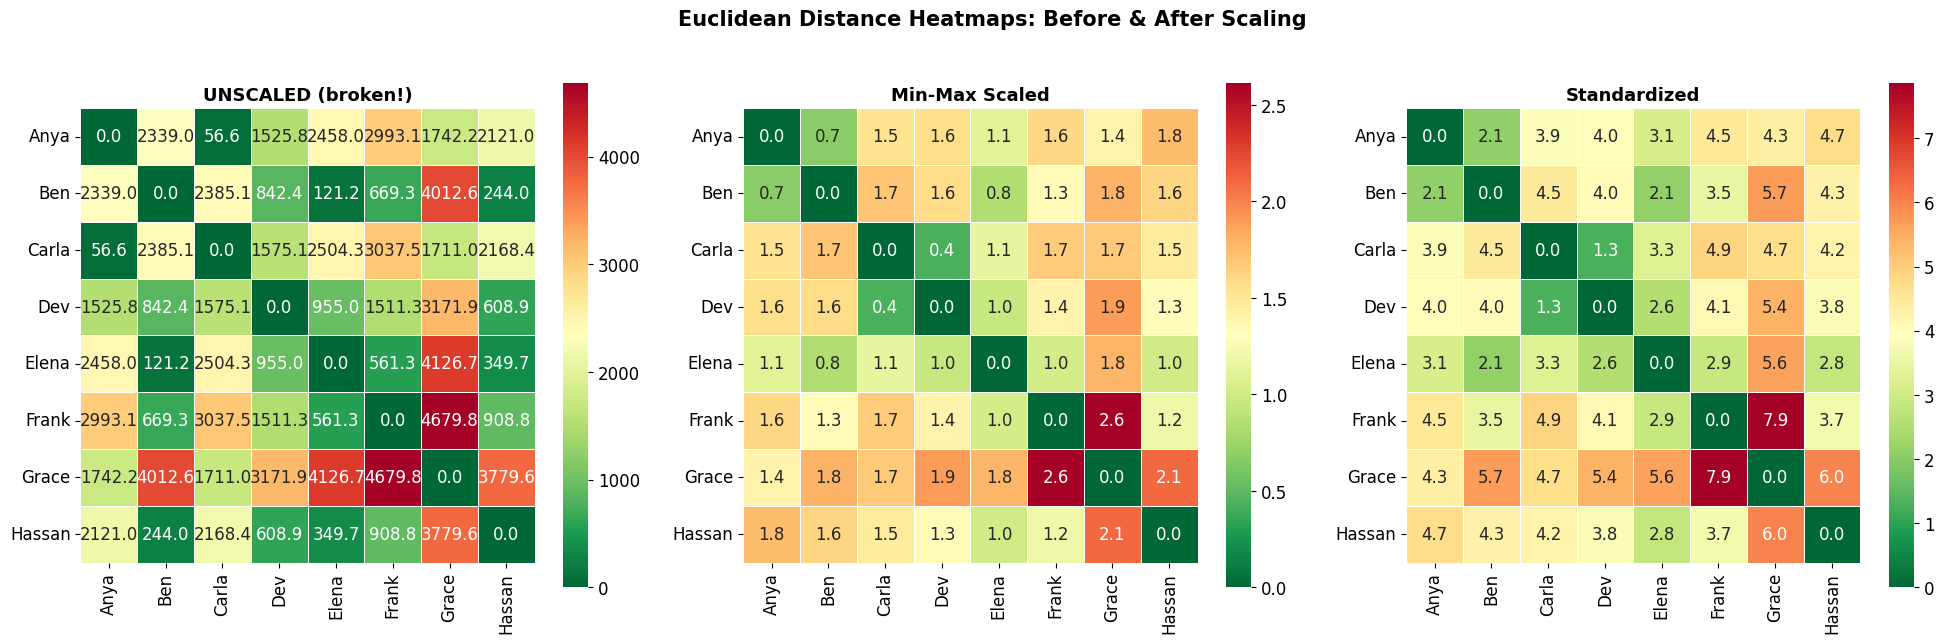

🏆 Anya's Closest Match Under Each Method:
-------------------------------------------------------
         Unscaled: #1  Carla (d=56.58)   #2    Dev (d=1525.84)
          Min-Max: #1    Ben (d=0.67)   #2  Elena (d=1.11)
     Standardized: #1    Ben (d=2.10)   #2  Elena (d=3.13)

🎉 SCALING FIXES THE PROBLEM!
   Unscaled:     Carla appears closest (WRONG — fooled by similar watch count/account age)
   After scaling: Ben is correctly identified as closest (CORRECT — similar genre taste!)

   By putting all features on the same scale, genre taste can finally
   compete fairly with behavioral features in the distance calculation.


In [ ]:
# THE PAYOFF: Does scaling fix Anya's recommendation?

minmax_distances = euclidean_distances(minmax_data)
standard_distances = euclidean_distances(standard_data)

fig, axes = plt.subplots(1, 3, figsize=(20, 6))

for ax, dist, title in zip(axes,
    [unscaled_distances, minmax_distances, standard_distances],
    ['UNSCALED (broken!)', 'Min-Max Scaled', 'Standardized']):

    sns.heatmap(dist, annot=True, fmt='.1f', xticklabels=user_names_list,
                yticklabels=user_names_list, cmap='RdYlGn_r', ax=ax,
                linewidths=0.5, square=True)
    ax.set_title(title, fontsize=13, fontweight='bold')

plt.suptitle("Euclidean Distance Heatmaps: Before & After Scaling",
             fontsize=15, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

# Show Anya's rankings under each method
print("🏆 Anya's Closest Match Under Each Method:")
print("-" * 55)
for label, dist_matrix in [("Unscaled", unscaled_distances),
                            ("Min-Max", minmax_distances),
                            ("Standardized", standard_distances)]:
    dists = [(user_names_list[i], dist_matrix[anya_idx][i])
             for i in range(len(user_names_list)) if i != anya_idx]
    dists.sort(key=lambda x: x[1])
    closest = dists[0]
    second = dists[1]
    print(f"   {label:>14}: #{1} {closest[0]:>6} (d={closest[1]:.2f})   #{2} {second[0]:>6} (d={second[1]:.2f})")

print()
print("🎉 SCALING FIXES THE PROBLEM!")
print("   Unscaled:     Carla appears closest (WRONG — fooled by similar watch count/account age)")
print("   After scaling: Ben is correctly identified as closest (CORRECT — similar genre taste!)")
print()
print("   By putting all features on the same scale, genre taste can finally")
print("   compete fairly with behavioral features in the distance calculation.")

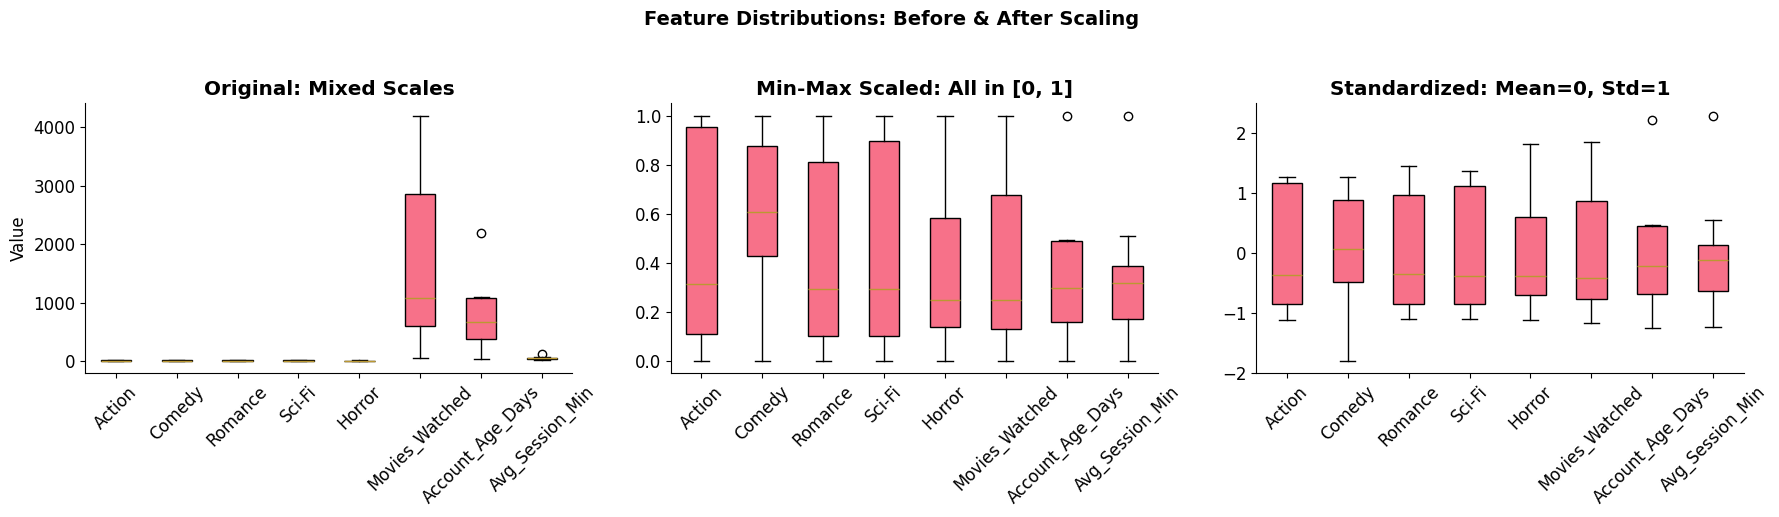

👀 Original: Movies_Watched towers over everything else — it dominates all distance calculations
   Min-Max: Everything squeezed into 0-1 — all features get a fair voice
   Standardized: Everything centered at 0 with unit spread — also fair, and more robust to outliers


In [ ]:
# Visual comparison: feature distributions before and after scaling

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

bp1 = axes[0].boxplot([expanded_df[f].values for f in expanded_features],
                       labels=expanded_features, vert=True, patch_artist=True)
axes[0].set_title('Original: Mixed Scales', fontweight='bold')
axes[0].tick_params(axis='x', rotation=45)
axes[0].set_ylabel('Value')

bp2 = axes[1].boxplot([minmax_df[f].values for f in expanded_features],
                       labels=expanded_features, vert=True, patch_artist=True)
axes[1].set_title('Min-Max Scaled: All in [0, 1]', fontweight='bold')
axes[1].tick_params(axis='x', rotation=45)

bp3 = axes[2].boxplot([standard_df[f].values for f in expanded_features],
                       labels=expanded_features, vert=True, patch_artist=True)
axes[2].set_title('Standardized: Mean=0, Std=1', fontweight='bold')
axes[2].tick_params(axis='x', rotation=45)

plt.suptitle('Feature Distributions: Before & After Scaling', fontsize=14, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

print("👀 Original: Movies_Watched towers over everything else — it dominates all distance calculations")
print("   Min-Max: Everything squeezed into 0-1 — all features get a fair voice")
print("   Standardized: Everything centered at 0 with unit spread — also fair, and more robust to outliers")

---

## 🤔 When to Use Which Scaler?

| Scenario | Use Min-Max | Use Standardization |
|----------|:-----------:|:------------------:|
| Neural networks (need bounded inputs) | ✅ | |
| Image pixel values | ✅ | |
| Features with known fixed bounds | ✅ | |
| Data has significant outliers | | ✅ |
| Algorithms assuming Gaussian-like data (SVM, Logistic Regression) | | ✅ |
| Distance-based methods (KNN, K-Means) | Either works | ✅ (usually safer) |
| Tree-based models (Random Forest, XGBoost) | 🚫 Not needed | 🚫 Not needed |

### 🌳 Wait — Trees Don't Need Scaling?

Correct! Decision trees, Random Forests, and Gradient Boosted Trees split on one feature at a time. They only care about the **order** of values, not their magnitude. So scaling is irrelevant for them.

**But**: KNN, K-Means, SVM, Neural Networks, PCA, and any distance/gradient-based method **absolutely needs scaling**.

> 🧠 **Rule of thumb:** If your model uses distances or gradients, **always scale your features**. If it's tree-based, you can skip it.

---
# 🎯 Putting It All Together: FlickPick's Recommendation Engine

Let's combine everything we've learned to build a simple but effective recommendation system.

**The Pipeline:**
1. Represent users as vectors ✓
2. Scale features so nothing gets bullied ✓
3. Use cosine similarity to find taste-twins ✓
4. Recommend movies that the taste-twin loved but our user hasn't seen

In [ ]:
# The full FlickPick recommendation pipeline

scaler = StandardScaler()
scaled_vectors = scaler.fit_transform(expanded_df.values)

similarity_matrix = cosine_similarity(scaled_vectors)
sim_df = pd.DataFrame(similarity_matrix, index=user_names_list, columns=user_names_list)

def recommend_for(user_name, top_n=3):
    """Find the top-N most similar users to a given user."""
    similarities = sim_df[user_name].drop(user_name).sort_values(ascending=False)

    print(f"\n🎬 Recommendations for {user_name}")
    print(f"   Taste Profile: {dict(zip(genres, expanded_users[user_name][:5]))}")
    print(f"   {'─' * 45}")

    for i, (match_name, sim_score) in enumerate(similarities.head(top_n).items()):
        angle = np.degrees(np.arccos(np.clip(sim_score, -1, 1)))
        print(f"   #{i+1} {match_name} (similarity: {sim_score:.3f}, angle: {angle:.1f}°)")
        print(f"      Taste: {dict(zip(genres, expanded_users[match_name][:5]))}")

    worst = similarities.tail(1)
    print(f"\n   ❌ Least compatible: {worst.index[0]} (similarity: {worst.values[0]:.3f})")

for user in ['Anya', 'Carla', 'Hassan']:
    recommend_for(user)


🎬 Recommendations for Anya
   Taste Profile: {'Action': 8.5, 'Comedy': 6.0, 'Romance': 2.0, 'Sci-Fi': 9.0, 'Horror': 1.0}
   ─────────────────────────────────────────────
   #1 Ben (similarity: 0.590, angle: 53.8°)
      Taste: {'Action': 9.0, 'Comedy': 5.5, 'Romance': 1.5, 'Sci-Fi': 8.5, 'Horror': 2.0}
   #2 Grace (similarity: 0.356, angle: 69.2°)
      Taste: {'Action': 9.0, 'Comedy': 8.5, 'Romance': 7.5, 'Sci-Fi': 9.5, 'Horror': 8.0}
   #3 Frank (similarity: -0.220, angle: 102.7°)
      Taste: {'Action': 2.0, 'Comedy': 1.5, 'Romance': 1.0, 'Sci-Fi': 2.0, 'Horror': 0.5}

   ❌ Least compatible: Hassan (similarity: -0.675)

🎬 Recommendations for Carla
   Taste Profile: {'Action': 2.0, 'Comedy': 8.0, 'Romance': 9.5, 'Sci-Fi': 1.5, 'Horror': 3.0}
   ─────────────────────────────────────────────
   #1 Dev (similarity: 0.845, angle: 32.4°)
      Taste: {'Action': 1.0, 'Comedy': 7.5, 'Romance': 9.0, 'Sci-Fi': 2.0, 'Horror': 2.5}
   #2 Grace (similarity: 0.212, angle: 77.8°)
      Taste: {'

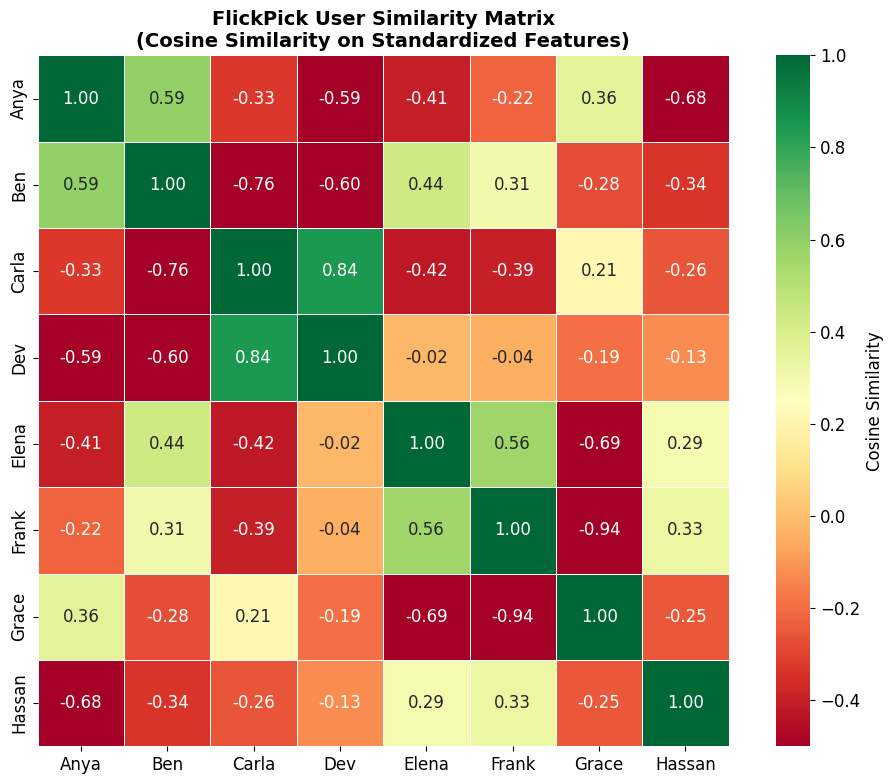

🎉 Our recommendation engine is complete!

📋 Summary of everything we learned:
   1. Vectors = numbers that represent real-world things
   2. Norms = how to measure the 'size' of a vector (building block for everything else)
   3. Euclidean Distance = L2 norm of the difference (straight-line gap)
   4. Manhattan Distance = L1 norm of the difference (grid-walk gap)
   5. Cosine Similarity = compares direction, divides out L2 norms to ignore magnitude
   6. Curse of Dimensionality = more features ≠ better; distances collapse
   7. Feature Scaling = level the playing field so all features contribute fairly


In [ ]:
# Final visualization: The complete similarity landscape

fig, ax = plt.subplots(figsize=(10, 8))

sns.heatmap(sim_df, annot=True, fmt='.2f', cmap='RdYlGn',
            linewidths=0.5, square=True, vmin=-0.5, vmax=1.0,
            cbar_kws={'label': 'Cosine Similarity'})
ax.set_title("FlickPick User Similarity Matrix\n(Cosine Similarity on Standardized Features)",
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("🎉 Our recommendation engine is complete!")
print()
print("📋 Summary of everything we learned:")
print("   1. Vectors = numbers that represent real-world things")
print("   2. Norms = how to measure the 'size' of a vector (building block for everything else)")
print("   3. Euclidean Distance = L2 norm of the difference (straight-line gap)")
print("   4. Manhattan Distance = L1 norm of the difference (grid-walk gap)")
print("   5. Cosine Similarity = compares direction, divides out L2 norms to ignore magnitude")
print("   6. Curse of Dimensionality = more features ≠ better; distances collapse")
print("   7. Feature Scaling = level the playing field so all features contribute fairly")

---
# 📋 Cheat Sheet: Everything at a Glance

## How It All Connects

```
                     ┌──────────────┐
                     │    VECTOR    │  ← Step 1: Represent things as numbers
                     └──────┬───────┘
                            │
                     ┌──────▼───────┐
                     │    NORMS     │  ← Building block: measure vector "size"
                     │  L1     L2   │
                     └──┬───────┬───┘
                        │       │
               ┌────────▼──┐ ┌──▼────────┐
               │ Manhattan  │ │ Euclidean  │  ← Distance = norm of the DIFFERENCE
               │ Distance   │ │ Distance   │
               │ (uses L1)  │ │ (uses L2)  │
               └────────────┘ └──┬─────────┘
                                 │
                          ┌──────▼───────┐
                          │   COSINE     │  ← Divides by L2 norms to compare
                          │  SIMILARITY  │    DIRECTION only
                          └──────────────┘
```

## Concepts Summary

| Concept | What It Does | FlickPick Analogy |
|---------|-------------|-------------------|
| **Vector** | Ordered list of numbers representing something | A user's genre ratings = their taste DNA |
| **L1 Norm** | Sum of absolute values (grid-walk length) | How far is this user from "rated nothing"? (walking) |
| **L2 Norm** | Square root of sum of squares (straight-line length) | How far is this user from "rated nothing"? (flying) |
| **Manhattan Distance** | L1 norm of the difference between two vectors | Grid-walk gap between two users' tastes |
| **Euclidean Distance** | L2 norm of the difference between two vectors | Straight-line gap between two users' tastes |
| **Cosine Similarity** | Dot product ÷ (L2 norms) → direction comparison | Do they like the same KIND of movies? |
| **Angle Between Vectors** | arccos(cosine similarity) | How far apart are their taste directions? |
| **Curse of Dimensionality** | Distances become meaningless in high dimensions | Adding too many features breaks recommendations |
| **Min-Max Scaling** | Rescale features to [0, 1] | Make genre ratings and watch counts comparable |
| **Standardization** | Rescale to mean=0, std=1 | Same goal, more robust to outliers |

## Decision Guide

```
                    ┌─ Comparing vectors? ─────── Cosine Similarity (direction matters)
                    │                                    │
                    │                              Need distance? → Euclidean (general)
                    │                                              → Manhattan (sparse data)
Your Task ──────────┤
                    │                              ┌─ Neural networks → Min-Max
                    │                              │
                    └─ Mixed-scale features? ──────┤─ Most ML models → Standardization
                                                   │
                                                   └─ Tree models → No scaling needed
```

## Key Takeaways

1. **Everything in ML starts with turning things into vectors**
2. **Norms are building blocks** — they power distances, cosine similarity, and regularization
3. **Distance ≠ Dissimilarity** when vectors have different magnitudes → use cosine similarity
4. **More features can hurt** → be thoughtful about dimensionality
5. **Always scale features** before using distance-based algorithms (we saw unscaled data pick the WRONG user!)
6. **No single metric is best** → choose based on what question you're answering

---

*Built with ❤️ at FlickPick — where every movie finds its audience.*